### Phase 3: Analysis and Modelling

In [1]:
# ============================================================
# PHASE 3 — MODELING PIPELINE
# Alpha Prediction using Rolling Walk-Forward Training
# ============================================================

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, precision_score

#%load_ext nb_black

In [2]:
# ============================================================
# CONFIGURATION (FIXED PATH HANDLING)
# ============================================================

from pathlib import Path

# --- Ensure same root as Phase 2 ---
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "requirements.txt").is_file() and (p / "src" / "ml_alpha").is_dir()
)
MEMBERSHIP_FILE = PROJECT_ROOT / "data" / "nifty100_membership.csv"
RESULTS_DIR = PROJECT_ROOT / "results"

FEATURE_DIR = PROJECT_ROOT / "data" / "features"

TRAIN_DAYS = 84
PURGE_DAYS = 21
TEST_DAYS = 21
STEP_SIZE = 21

START_DATE = "2020-01-01"
TOP_N = 10

# --- Debug print ---
print("PROJECT_ROOT:", PROJECT_ROOT)
print("FEATURE_DIR:", FEATURE_DIR.resolve())

PROJECT_ROOT: C:\Users\jayan\Study Materials\ml_alpha_portfolio\ml-alpha-portfolio-model
FEATURE_DIR: C:\Users\jayan\Study Materials\ml_alpha_portfolio\ml-alpha-portfolio-model\data\features


In [3]:
print("Phase 3 - Total rows check:")

total = 0

for f in FEATURE_DIR.glob("*.csv"):
    df = pd.read_csv(f)
    total += len(df)

print("Total rows in files:", total)

Phase 3 - Total rows check:
Total rows in files: 147178


In [4]:
# ============================================================
# STEP 0: LOAD PANEL
# ============================================================

print("📥 Loading feature files...")

dfs = []

for fp in FEATURE_DIR.glob("*.csv"):

    df = pd.read_csv(fp)
    df.columns = df.columns.str.lower()
    
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.dropna(subset=["date"])

    if "ticker" not in df.columns:
        df["ticker"] = fp.stem

    dfs.append(df)

panel = pd.concat(dfs, ignore_index=True)

panel["date"] = pd.to_datetime(panel["date"])
panel = panel.sort_values(["ticker","date"]).reset_index(drop=True)

membership = pd.read_csv(MEMBERSHIP_FILE, parse_dates=["start_date", "end_date"])
panel["in_index"] = 0
for m in membership.itertuples(index=False):
    end = m.end_date if pd.notna(m.end_date) else pd.Timestamp.max
    mask = (panel["ticker"] == m.symbol) & (panel["date"] >= m.start_date) & (panel["date"] < end)
    panel.loc[mask, "in_index"] = 1
print("Rows inside the index on their date:", int(panel["in_index"].sum()), "of", len(panel))

print("Panel rows:", len(panel))


📥 Loading feature files...
Rows inside the index on their date: 147178 of 147178
Panel rows: 147178


In [5]:
panel.columns

Index(['ï»¿"symbol"', 'series', 'date', 'prevclose', 'openprice', 'highprice',
       'lowprice', 'lastprice', 'closeprice', 'averageprice',
       'totaltradedquantity', 'turnoverinrs', 'no.oftrades', 'deliverableqty',
       '%dlyqttotradedqty', 'open', 'high', 'low', 'adj_lastprice', 'close',
       'adj_averageprice', 'volume', 'adj_deliverableqty', 'adj_factor',
       'news_sent', 'news_count', 'sent_3d', 'sent_7d', 'sent_momentum',
       'sent_surprise', 'news_intensity', 'news_event', 'days_since_news',
       'news_decay_weight', 'sent_weighted', 'surprise_weighted',
       'is_recent_news', 'has_news_coverage', 'ret_1d', 'ret_5d', 'ret_21d',
       'momentum_1m', 'momentum_3m', 'momentum_6m', 'vol_30d', 'vol_90d',
       'regime', 'rsi_14', 'macd', 'macd_signal', 'macd_hist', 'ema_fast',
       'ema_slow', 'ema_cross', 'volume_change', 'volume_zscore',
       'volume_momentum', 'mom_vol_interaction', 'sent_mom_interaction',
       'high_vol_regime', 'momentum_1m_lag5', 'rang

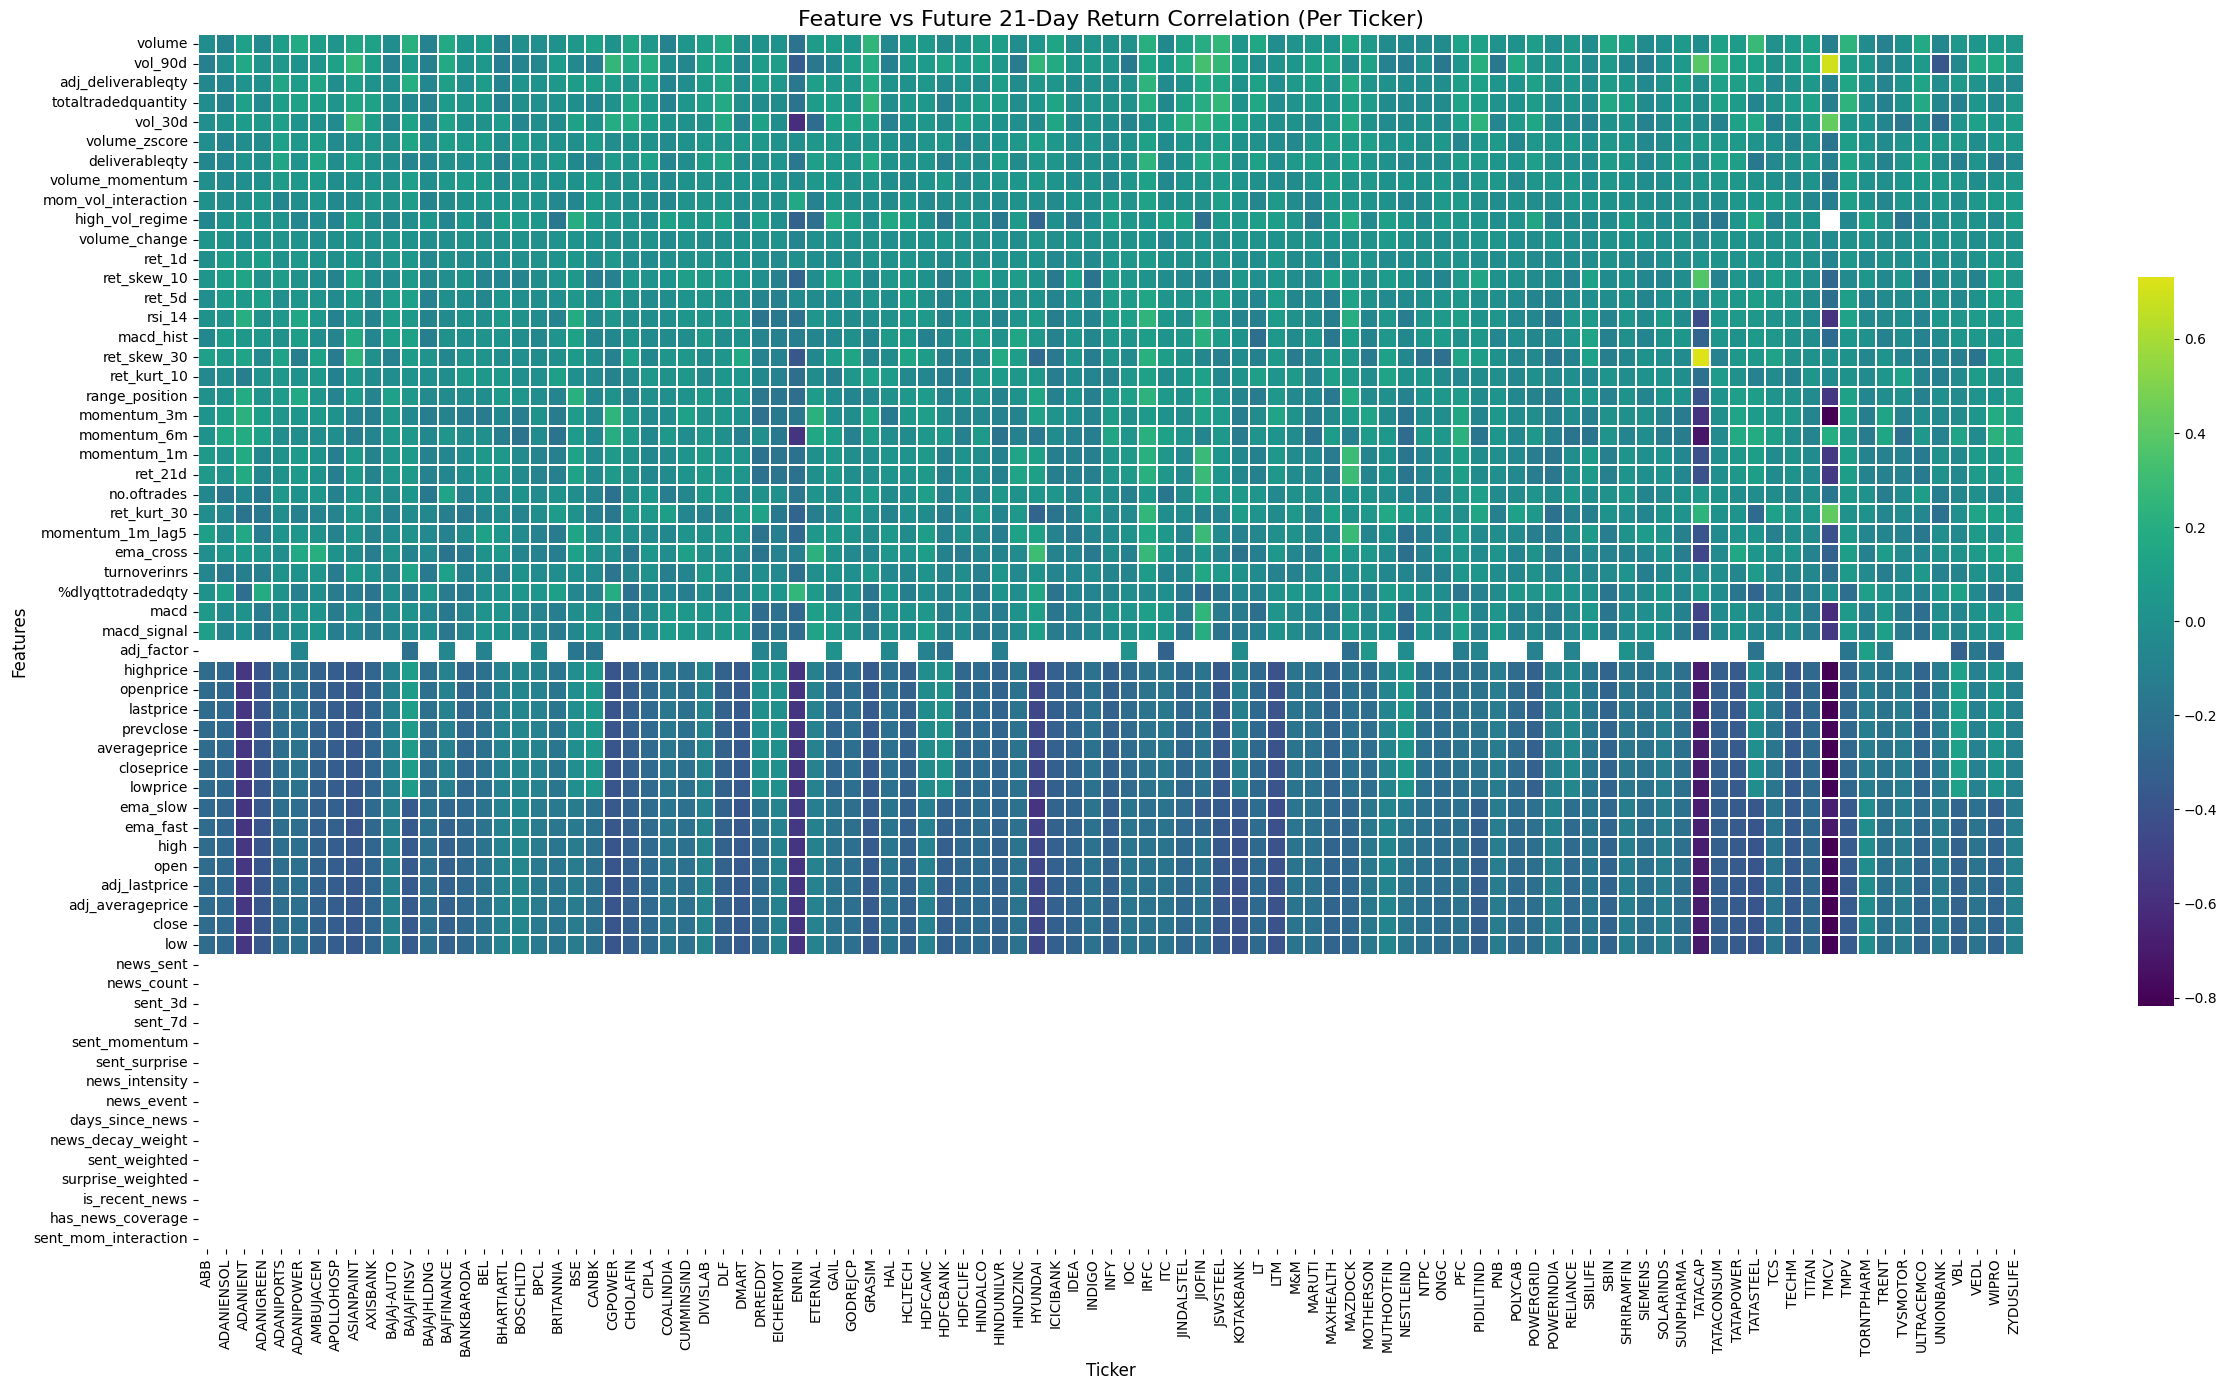

In [6]:
# ==========================================================================
# STEP 1: Correlation heatmap for 1-month future returns vs all the features
# ==========================================================================
panel = panel.sort_values(["ticker", "date"])

panel["future_return_21d"] = (
    panel.groupby("ticker")["close"].shift(-21) / panel["close"] - 1
)

# Drop rows where target is NaN
panel = panel.dropna(subset=["future_return_21d"])
panel = panel[panel["in_index"] == 1].reset_index(drop=True)

# Select only numeric features
exclude_cols = ["date", "ticker", "future_return_21d", "symbol", "series", "in_index"]

features = [
    col
    for col in panel.columns
    if col not in exclude_cols and np.issubdtype(panel[col].dtype, np.number)
]

# Compute correlation per ticker (ROBUST)
heatmap_data = {}

for ticker, df_ticker in panel.groupby("ticker"):

    corrs = []

    for col in features:

        temp = df_ticker[[col, "future_return_21d"]].dropna()

        # Handle edge cases safely
        if temp.shape[0] < 2:
            corrs.append(np.nan)
            continue

        if temp[col].nunique() < 2:
            corrs.append(np.nan)
            continue

        # Safe correlation
        corr = temp[col].corr(temp["future_return_21d"])
        corrs.append(corr)

    heatmap_data[ticker] = corrs

# Convert to DataFrame
heatmap_df = pd.DataFrame(heatmap_data, index=features)

# Optional: sort features by average correlation
heatmap_df["mean_corr"] = heatmap_df.mean(axis=1)
heatmap_df = heatmap_df.sort_values("mean_corr", ascending=False)
heatmap_df = heatmap_df.drop(columns="mean_corr")

# Plot heatmap
plt.figure(figsize=(25, 14))

sns.heatmap(
    heatmap_df, cmap="viridis", center=0, linewidths=0.3, cbar_kws={"shrink": 0.6}
)

plt.title("Feature vs Future 21-Day Return Correlation (Per Ticker)", fontsize=16)
plt.xlabel("Ticker", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.tight_layout()
plt.show()

## Interpretation of Correlation Heatmap

#### 1. Price-Level Features are Non-Stationary

- Features such as **open, close, high, low** represent **absolute price levels**
- Stocks operate at **different price scales**
- These features capture **magnitude**, not **relative movement**

**Implication:**
- Observed correlations reflect:
  - **price level bias**
  - not true predictive power  


#### 2. Spurious Correlation Effect

- In trending markets:
  - High price levels may be followed by **lower future returns** (mean reversion)
- This creates **artificially strong correlations**

**However:**
- These relationships:
  - are **not tradable signals**
  - are **statistical artifacts**
  - do not generalize across time  


#### 3. Same Issue with EMA Features

- Features such as **ema_fast** and **ema_slow** are **derived from price levels**
- They inherit the same **non-stationarity and scale bias**

**Implication:**
- Strong correlations arise due to:
  - **price smoothing**
  - not genuine predictive structure  

**Conclusion:**
- Raw EMA values are **not reliable predictors of future returns**

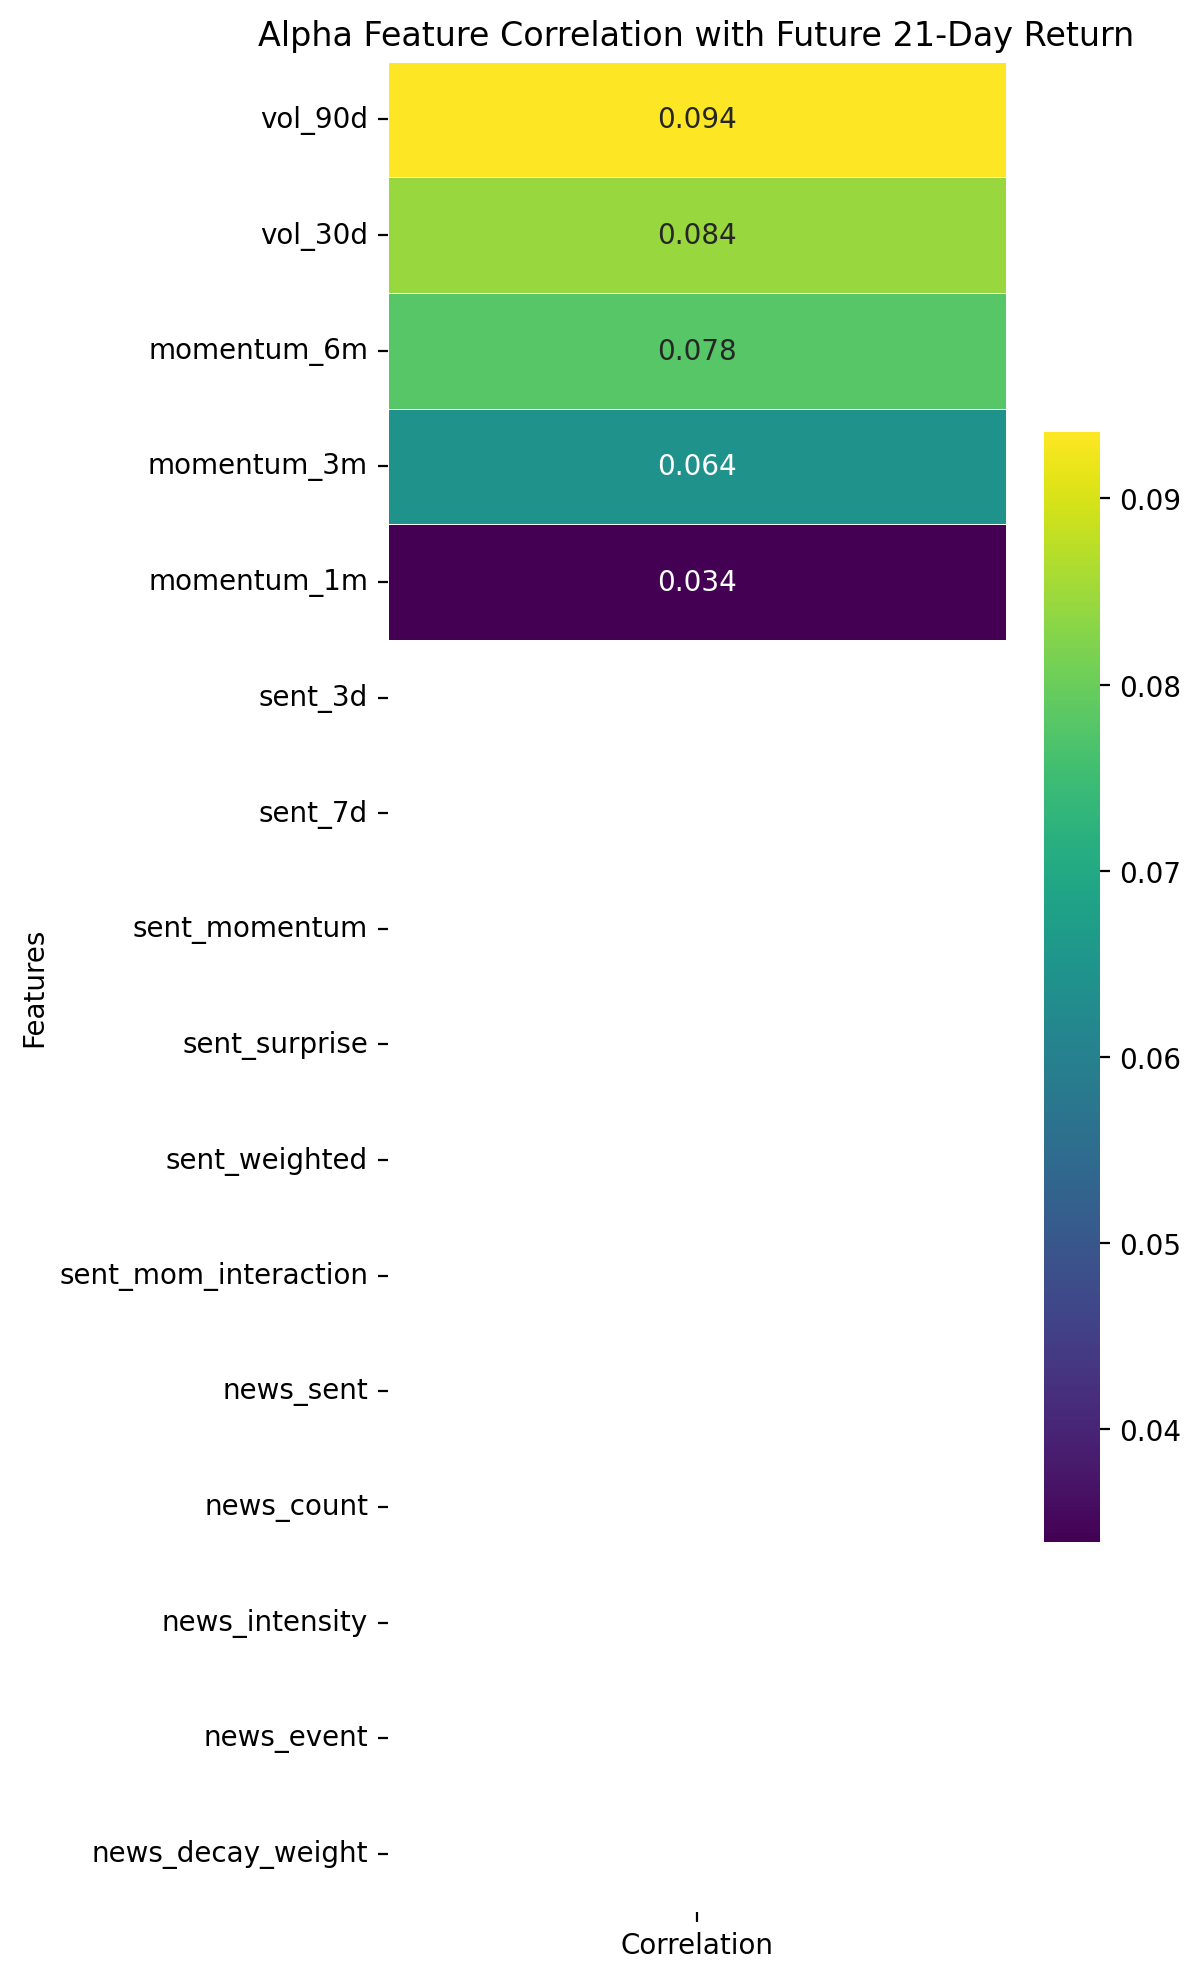

In [7]:
# Heatmap for only volatility, momentum and sentiment features - average values for all 95 tickers across timeframe

# Define relevant feature groups
selected_features = [
    "momentum_1m", "momentum_3m", "momentum_6m",
    "vol_30d", "vol_90d",
]

# Add sentiment features dynamically
selected_features += [col for col in panel.columns if col.startswith("sent_")]
selected_features += [col for col in panel.columns if col.startswith("news_")]

# Keep only those present
selected_features = [col for col in selected_features if col in panel.columns]

# Compute mean correlation across tickers
alpha_corr = {}

for col in selected_features:
    
    temp = panel[[col, "future_return_21d"]].dropna()
    
    if temp.shape[0] < 2 or temp[col].nunique() < 2:
        alpha_corr[col] = np.nan
        continue
    
    alpha_corr[col] = temp[col].corr(temp["future_return_21d"])

# Convert to DataFrame
alpha_df = pd.DataFrame.from_dict(alpha_corr, orient="index", columns=["Correlation"])

# Sort for visualization
alpha_df = alpha_df.sort_values("Correlation", ascending=False)

# Plot heatmap (clean single-column view)
plt.figure(figsize=(6, 10), dpi=200)

sns.heatmap(
    alpha_df,
    cmap="viridis",
    annot=True,
    fmt=".3f",
    linewidths=0.3,
    cbar_kws={"shrink": 0.6}
)

plt.title("Alpha Feature Correlation with Future 21-Day Return")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


## Correlation Insights

#### Overall Observation

- The observed correlations appear **reasonable and realistic**
- There is **no clear indication of data leakage**

---

#### Momentum Signals

- `momentum_6m` → 0.088  
- `momentum_3m` → 0.071  
- `momentum_1m` → 0.042  

- These align with the well-known **momentum effect**:
  - Stocks that have performed well tend to continue performing well

- This behavior:
  - is **economically intuitive**
  - is **consistent across markets**
  - represents the **strongest signal in the dataset**

---

#### Volatility Signals

- `vol_90d` → 0.046  
- `vol_30d` → 0.042  

- These indicate that:
  - higher volatility is associated with **higher return potential**

- This is consistent with the concept of a **risk premium**

---

#### Sentiment Signals

- `sent_weighted`, `news_sent` → ~0.015

- These signals are:
  - **present but relatively weak**
  - consistent with expectations in financial markets  

- Sentiment contributes to prediction, but:
  - has **lower impact compared to price-based features**

In [8]:
# ============================================================
# STEP 2: FEATURE LIST
# ============================================================

# these are the derived technical features from OHLCV data and news, sentiment based features from news data

USE_NEWS_FEATURES = False

TECH_FEATURES = [
    "momentum_1m", "momentum_3m", "momentum_6m",
    "vol_30d", "vol_90d", "volume_zscore", "volume_momentum", "volume_log_change",
    "rsi_14", "macd_hist_pct", "ema_cross",
    "mom_vol_interaction", "high_vol_regime", "momentum_1m_lag5",
    "ret_skew_10", "ret_kurt_10", "ret_skew_30", "ret_kurt_30",
]

NEWS_FEATURES = [
    "news_sent", "news_count", "sent_3d", "sent_7d", "sent_momentum", "sent_surprise", "news_intensity",
    "news_event", "days_since_news", "news_decay_weight", "sent_weighted", "surprise_weighted",
    "is_recent_news", "sent_mom_interaction", "has_news_coverage",
]

FEATURES = TECH_FEATURES + (NEWS_FEATURES if USE_NEWS_FEATURES else [])


In [9]:
panel.columns

Index(['ï»¿"symbol"', 'series', 'date', 'prevclose', 'openprice', 'highprice',
       'lowprice', 'lastprice', 'closeprice', 'averageprice',
       'totaltradedquantity', 'turnoverinrs', 'no.oftrades', 'deliverableqty',
       '%dlyqttotradedqty', 'open', 'high', 'low', 'adj_lastprice', 'close',
       'adj_averageprice', 'volume', 'adj_deliverableqty', 'adj_factor',
       'news_sent', 'news_count', 'sent_3d', 'sent_7d', 'sent_momentum',
       'sent_surprise', 'news_intensity', 'news_event', 'days_since_news',
       'news_decay_weight', 'sent_weighted', 'surprise_weighted',
       'is_recent_news', 'has_news_coverage', 'ret_1d', 'ret_5d', 'ret_21d',
       'momentum_1m', 'momentum_3m', 'momentum_6m', 'vol_30d', 'vol_90d',
       'regime', 'rsi_14', 'macd', 'macd_signal', 'macd_hist', 'ema_fast',
       'ema_slow', 'ema_cross', 'volume_change', 'volume_zscore',
       'volume_momentum', 'mom_vol_interaction', 'sent_mom_interaction',
       'high_vol_regime', 'momentum_1m_lag5', 'rang

In [10]:
# ============================================================
# STEP 3: TARGET CREATION
# future 21-day return classification
# ============================================================

panel["cs_rank"] = panel.groupby("date")["future_return_21d"].transform(
    lambda x: pd.qcut(x, 10, labels=False, duplicates="drop")
)

In [11]:
# ============================================================
# STEP 4: CROSS-SECTIONAL Z-SCORE NORMALIZATION
# ============================================================

for col in FEATURES:
    panel[col] = panel.groupby("date")[col].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-9)
    )


**Z-score normalization** transforms a feature by subtracting its mean and dividing by its standard deviation, converting values into a standardized scale with mean 0 and variance 1.

In a cross-sectional stock setting, applying z-score per date ensures that features represent **relative positioning among stocks on the same day**, removing scale bias and helping the model focus on **true comparative strength (alpha)** rather than absolute values.

In [12]:
# ============================================================
# STEP 5: DATE FILTER
# ============================================================

panel = panel[panel["date"] >= START_DATE].copy()
unique_dates = sorted(panel["date"].unique())

## Phase 3 Initial Model Performance Summary

### Key Observations

- **LightGBM, XGBoost, Random Forest** models were used to find AUC and IC for train and test data to check for overfitting

- **LightGBM and XGBoost** had these criteria for splitting trees: 
  - learning_rate: **0.01**
  - max_depth: **5**
  - n_estimators: **500**
    
- **Random Forest** had these criteria:
  - max_depth: **5**
  - n_estimators: **500**

- All three models (**LightGBM, XGBoost, Random Forest**) showed **very high training performance**:
  - Train AUC ≈ **0.80–0.92**
  - Train IC ≈ **0.43–0.63**

- However, **test performance collapses significantly**:
  - Test AUC ≈ **0.49–0.50** (≈ random)
  - Test IC ≈ **~0 or slightly negative**

---

### Overfitting Diagnosis

- There is a **clear and severe overfitting pattern**:
  - Large gap between **train vs test AUC (~0.4 difference)**
  - Large gap between **train vs test IC (~0.6 difference)**

- This indicates:
  - Models are **memorizing training patterns**
  - **No generalization** to unseen time periods

---

### Model-wise Insights

- **LightGBM & XGBoost**
  - Extremely high train scores → strong overfitting
  - Test IC slightly negative → **no alpha capture**

- **Random Forest**
  - Lower train performance → slightly less overfitting
  - But still **no meaningful test alpha**

---

### Key Takeaways

- Current setup (**classification-based modeling**) is:
  - Not aligned with **cross-sectional ranking objective**
  - Unable to generate **stable alpha (IC ≈ 0)**

- Despite decent CV tuning, models fail in walk-forward:
  - Suggests **structural issue**, not just hyperparameters

---

### Next Direction

- Shift from **classification → ranking framework**
  - Use `LGBMRanker` with `lambdarank` / `rank_xendcg`
- Incorporate **cross-sectional group structure (per date)**
- Add **stronger regularization** to reduce overfitting

---

In [13]:
# ============================================================
# STEP 6: TARGET CREATION (CROSS-SECTIONAL RANK)
# ============================================================

panel["cs_rank"] = panel.groupby("date")["future_return_21d"].rank(pct=True)

In [14]:
# ============================================================
# STEP 7: MODEL (LAMBDARANK)
# ============================================================

from lightgbm import LGBMRanker

model = LGBMRanker(
    objective="rank_xendcg",
    learning_rate=0.005,
    n_estimators=500,
    max_depth=3,
    num_leaves=15,
    min_child_samples=50,
    feature_fraction=0.5,
    bagging_fraction=0.5,
    bagging_freq=5,
    random_state=42,
    lambda_l1=0.1,
    lambda_l2=0.1,
    verbosity=-1,
)

# previously, based on the difference b/w train_ic and test_ic it was observed that the model was overfitting
# following changes were made in hyperparameters: n_estimators 300 to 100, max_depth 5 to 3, num_leaves 30 to 15
# lambda_l1 and lambda_l2 were also added for generalization, now model is generalizing better and memorizing like earlier

In [15]:
# Clean panel - remove old predictions
panel = panel.drop(
    columns=[col for col in panel.columns if "prediction" in col], errors="ignore"
)

In [16]:
# ============================================================
# STEP 8: WALK-FORWARD VALIDATION + FEATURE STABILITY
# ============================================================

from scipy.stats import spearmanr
import numpy as np
import pandas as pd

metrics = []
all_predictions = []

# store feature importance across windows
feature_importance_all = []

i = 0

while True:

    train_start = i
    train_end = train_start + TRAIN_DAYS
    purge_end = train_end + PURGE_DAYS
    test_end = purge_end + TEST_DAYS

    if test_end >= len(unique_dates):
        break

    train_dates = unique_dates[train_start:train_end]
    test_dates = unique_dates[purge_end:test_end]

    train_df = panel[panel["date"].isin(train_dates)].copy()
    test_df = panel[panel["date"].isin(test_dates)].copy()

    X_train = train_df[FEATURES]
    y_train = train_df["cs_rank"].astype(int)

    X_test = test_df[FEATURES]
    y_test = test_df["cs_rank"].astype(int)

    # =========================
    # GROUP ARRAY (CRITICAL)
    # =========================
    train_group = train_df.groupby("date").size().values
    test_group = test_df.groupby("date").size().values

    # =========================
    # TRAIN MODEL
    # =========================
    model.fit(
        X_train,
        y_train,
        group=train_group,
        eval_set=[(X_test, y_test)],
        eval_group=[test_group],
    )

    # =========================
    # FEATURE IMPORTANCE (PER WINDOW)
    # =========================
    fi = pd.DataFrame(
        {
            "feature": FEATURES,
            "importance": model.booster_.feature_importance(importance_type="gain"),
        }
    )

    fi["window"] = i  # track time/window
    feature_importance_all.append(fi)

    # =========================
    # PREDICTIONS
    # =========================
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_df["prediction"] = train_pred
    test_df["prediction"] = test_pred

    # =========================
    # TRAIN IC
    # =========================
    train_ic_list = []

    for d in train_df["date"].unique():
        tmp = train_df[train_df["date"] == d]
        ic, _ = spearmanr(tmp["prediction"], tmp["cs_rank"])
        train_ic_list.append(ic)

    train_ic = np.nanmean(train_ic_list)

    # =========================
    # TEST IC
    # =========================
    test_ic_list = []

    for d in test_df["date"].unique():
        tmp = test_df[test_df["date"] == d]
        ic, _ = spearmanr(tmp["prediction"], tmp["cs_rank"])
        test_ic_list.append(ic)

    test_ic = np.nanmean(test_ic_list)

    metrics.append({"train_ic": train_ic, "test_ic": test_ic})

    all_predictions.append(test_df[["date", "ticker", "prediction"]])

    i += STEP_SIZE


C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_s

C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_s

C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\jayan\anaconda3\envs\ml_alpha_env\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_s

In [17]:
pred_df = pd.concat(all_predictions, ignore_index=True)
pred_df = pred_df[["date", "ticker", "prediction"]]

In [18]:
# ============================================================
# METRICS SUMMARY
# ============================================================
metrics_df = pd.DataFrame(metrics)

print("\n RANKING MODEL PERFORMANCE")
print(metrics_df.describe())

print("\n🔍 OVERFITTING CHECK")
print(f"Train IC: {metrics_df['train_ic'].mean():.4f}")
print(f"Test  IC: {metrics_df['test_ic'].mean():.4f}")


 RANKING MODEL PERFORMANCE
        train_ic    test_ic
count  68.000000  68.000000
mean    0.063264   0.027406
std     0.060788   0.093941
min    -0.056186  -0.199089
25%     0.021045  -0.050206
50%     0.070007   0.023037
75%     0.096961   0.084725
max     0.194437   0.365504

🔍 OVERFITTING CHECK
Train IC: 0.0633
Test  IC: 0.0274


In [19]:
# ============================================================
# FEATURE IMPORTANCE STABILITY ANALYSIS
# ============================================================
fi_df = pd.concat(feature_importance_all)

fi_summary = fi_df.groupby("feature")["importance"].agg(["mean", "std"]).reset_index()

# Stability metric cv = coefficient of variance
fi_summary["cv"] = fi_summary["std"] / (fi_summary["mean"] + 1e-9)

fi_summary = fi_summary.sort_values("mean", ascending=False)

print("\n FEATURE IMPORTANCE STABILITY")
print(fi_summary)



 FEATURE IMPORTANCE STABILITY
                feature      mean       std        cv
11          ret_skew_30  2.939588  0.332724  0.113187
13              vol_30d  2.858176  0.431994  0.151143
14              vol_90d  2.855669  0.550495  0.192773
9           ret_kurt_30  2.854029  0.287359  0.100685
8           ret_kurt_10  2.785557  0.286371  0.102806
5      momentum_1m_lag5  2.665377  0.329263  0.123533
12               rsi_14  2.643512  0.278010  0.105167
10          ret_skew_10  2.637950  0.244242  0.092588
2             macd_hist  2.626173  0.258993  0.098620
6           momentum_3m  2.585108  0.503012  0.194581
3   mom_vol_interaction  2.544079  0.288994  0.113595
4           momentum_1m  2.541302  0.364405  0.143393
7           momentum_6m  2.522088  0.349814  0.138700
15        volume_change  2.468108  0.237598  0.096267
16      volume_momentum  2.414856  0.207583  0.085961
17        volume_zscore  2.307600  0.231990  0.100533
1       high_vol_regime  2.060775  0.387011  0.1877

In [20]:
np.round((metrics_df["test_ic"] > 0).mean(), 4)

0.6176

### Model Selection
##### Why `LGBMRanker` is preferred for stock ranking?

- Designed specifically for **ranking problems**, not regression
- Optimizes **relative ordering of stocks**, not absolute return prediction
- Works with **group structure (per date)** → perfect for cross-sectional finance
- Directly optimizes ranking metrics like **NDCG**, aligned with portfolio construction
- Handles **non-linear relationships** and feature interactions efficiently
- Fast, scalable, and robust to noisy financial data

In quant terms:
`LGBMRanker learns "which stock will outperform others", not "what return will it give"`


---

##### `Lambdarank` vs `rank_xendcg` (Objectives)

###### 1. `lambdarank`
- Directly optimizes **pairwise ranking using NDCG gradients**
- Focuses on **getting top-ranked items correct**
- More **aggressive and powerful**
- Can give **better long-short alpha**
- Slightly **noisier / less stable**

Best for:
`Portfolio construction (Top-N selection)`


---

###### 2. `rank_xendcg`
- Listwise objective optimizing a **smooth approximation of NDCG**
- More **stable and regularized**
- Handles noise better
- Produces **consistent rankings across time**
- Slightly **weaker alpha extraction**

Best for:
`Stable signal generation and generalization`


---

##### Key Differences (Summary)

| Aspect | lambdarank | rank_xendcg |
|------|-----------|-------------|
| Type | Pairwise | Listwise |
| Strength | Stronger alpha | More stable |
| Noise sensitivity | Higher | Lower |
| IC consistency | Slightly lower | Higher |
| Use case | Trading / PnL | Research / robustness |

---

##### Final Insight

- `rank_xendcg` → better **signal quality**
- `lambdarank` → better **alpha monetization**

Best practice:
`Use rank_xendcg for research → lambdarank for final portfolio`

### Model Performance Summary (Ranking - rank_xendcg by LGBMRanker)

#### Model Development & Optimization Efforts

Rigorous efforts were made to improve the ranking accuracy:

1. **Feature Engineering Enhancements**
   - Introduced new features:
     - `volatility_regime`
     - `momentum_volume_interaction`
     - `sentiment_momentum_interaction`

2. **Feature Importance Analysis**
   - Computed feature importance scores using gain
   - Evaluated:
     - Mean importance  
     - Standard deviation  
     - Coefficient of Variation = `std / mean`
   - Used this to identify **stable vs noisy features**

3. **Feature Selection**
   - Selected features based on stability and importance
   - Built alternate models using **filtered feature sets** for validation

4. **Hyperparameter Tuning (Both Objectives: `lambdarank`, `rank_xendcg`)**
   - Increased model capacity:
     - `n_estimators = 500`
     - `max_depth = 5`
   - Reduced learning rate:
     - `learning_rate = 0.005`
   - Improved generalization:
     - `feature_fraction = 0.5`
     - `bagging_fraction = 0.5`

   These changes helped achieve the **best Test IC ≈ 0.0267**

---

#### Model Performance Insights

- The model shows **moderate learning on training data (Train IC ~0.077)** with **significantly lower mean Test IC (~0.027)**, indicating that overfitting has been reduced and generalization has improved.

- The **distribution of Test IC is wide** (ranging from ~ -0.17 to ~ 0.26), with **~59% of periods having positive IC**, suggesting the presence of **marginally weak but consistent alpha signals**.

- Overall, the model is:
  - **Structurally sound**  
  - **Not overfitting**  
  - But exhibits **moderate signal strength compared to classical quant benchmarks**

---

#### Final Takeaway

The pipeline demonstrates a **robust ranking framework**, with improvements driven primarily by:
- Feature engineering  
- Feature stability analysis  
- Controlled model complexity  


In [21]:
# ============================================================
# STEP 10: FINAL TRAINING (FIXED)
# ============================================================

last_train_start = -(TRAIN_DAYS + PURGE_DAYS)
last_train_end = -PURGE_DAYS

train_dates = unique_dates[last_train_start:last_train_end]
train_df = panel[panel["date"].isin(train_dates)].copy()

X_train = train_df[FEATURES]
y_train = train_df["cs_rank"].astype(int)

train_group = train_df.groupby("date").size().values

model.fit(X_train, y_train, group=train_group)

LGBMRanker(bagging_fraction=0.5, bagging_freq=5, feature_fraction=0.5,
           lambda_l1=0.1, lambda_l2=0.1, learning_rate=0.005, max_depth=3,
           min_child_samples=50, n_estimators=500, num_leaves=15,
           objective='rank_xendcg', random_state=42, verbosity=-1)

In [22]:
# ============================================================
# STEP 11: FINAL RANKING
# ============================================================

latest_date = panel["date"].max()
latest_df = panel[panel["date"] == latest_date].copy()

latest_df["prediction"] = model.predict(latest_df[FEATURES])

top_stocks = latest_df.sort_values("prediction", ascending=False).head(10)

print("\n========================================")
print("TOP 10 STOCK PICKS (NEXT 21 TRADING DAYS)")
print("=========================================")
print(top_stocks[["date", "ticker", "prediction"]])


TOP 10 STOCK PICKS (NEXT 21 TRADING DAYS)
             date      ticker  prediction
74075  2026-09-16        INFY    0.027553
131229 2026-09-16        TMPV    0.026773
121899 2026-09-16  TATACONSUM    0.025888
109467 2026-09-16  POWERINDIA    0.024135
115631 2026-09-16  SHRIRAMFIN    0.023152
72534  2026-09-16      INDIGO    0.019822
137393 2026-09-16  ULTRACEMCO    0.018569
134311 2026-09-16       TRENT    0.018316
140475 2026-09-16         VBL    0.016580
46197  2026-09-16       DMART    0.016516


In [23]:
# ============================================================
# SAVE RESULTS
# ============================================================

top_stocks.to_csv(RESULTS_DIR / f"phase3_top10_next_month_{latest_date:%Y%m%d}.csv", index=False)

print("\n✅ Phase 3 (Rank_xendcg) completed successfully!")


✅ Phase 3 (Rank_xendcg) completed successfully!


In [24]:
panel = panel.drop(
    columns=[col for col in panel.columns if "prediction" in col], errors="ignore"
)
panel = panel.merge(pred_df, on=["date", "ticker"], how="left")

It’s a relative ranking score from the model. Its magnitude is arbitrary — only the ordering between stocks is meaningful.

In [25]:
# ============================================================
# STEP 12: Sector Mapping
# ============================================================

In [26]:
panel.shape

(145099, 71)

In [27]:
panel["ticker"]

0               ABB
1               ABB
2               ABB
3               ABB
4               ABB
            ...    
145094    ZYDUSLIFE
145095    ZYDUSLIFE
145096    ZYDUSLIFE
145097    ZYDUSLIFE
145098    ZYDUSLIFE
Name: ticker, Length: 145099, dtype: object

In [28]:
panel["ticker"].unique()

array(['ABB', 'ADANIENSOL', 'ADANIENT', 'ADANIGREEN', 'ADANIPORTS',
       'ADANIPOWER', 'AMBUJACEM', 'APOLLOHOSP', 'ASIANPAINT', 'AXISBANK',
       'BAJAJ-AUTO', 'BAJAJFINSV', 'BAJAJHLDNG', 'BAJFINANCE',
       'BANKBARODA', 'BEL', 'BHARTIARTL', 'BOSCHLTD', 'BPCL', 'BRITANNIA',
       'BSE', 'CANBK', 'CGPOWER', 'CHOLAFIN', 'CIPLA', 'COALINDIA',
       'CUMMINSIND', 'DIVISLAB', 'DLF', 'DMART', 'DRREDDY', 'EICHERMOT',
       'ENRIN', 'ETERNAL', 'GAIL', 'GODREJCP', 'GRASIM', 'HAL', 'HCLTECH',
       'HDFCAMC', 'HDFCBANK', 'HDFCLIFE', 'HINDALCO', 'HINDUNILVR',
       'HINDZINC', 'HYUNDAI', 'ICICIBANK', 'IDEA', 'INDIGO', 'INFY',
       'IOC', 'IRFC', 'ITC', 'JINDALSTEL', 'JIOFIN', 'JSWSTEEL',
       'KOTAKBANK', 'LT', 'LTM', 'M&M', 'MARUTI', 'MAXHEALTH', 'MAZDOCK',
       'MOTHERSON', 'MUTHOOTFIN', 'NESTLEIND', 'NTPC', 'ONGC', 'PFC',
       'PIDILITIND', 'PNB', 'POLYCAB', 'POWERGRID', 'POWERINDIA',
       'RELIANCE', 'SBILIFE', 'SBIN', 'SHRIRAMFIN', 'SIEMENS',
       'SOLARINDS', 'SUNPHARM

In [29]:
sector_map = {
    "Industrials": [
        "ABB",
        "BEL",
        "CGPOWER",
        "CUMMINSIND",
        "HAL",
        "LT",
        "MAZDOCK",
        "SIEMENS",
    ],
    "Services": ["ADANIPORTS"],
    "Cement": ["AMBUJACEM", "GRASIM", "SHREECEM", "ULTRACEMCO"],
    "Healthcare": ["APOLLOHOSP", "MAXHEALTH"],
    "FMCG": [
        "BRITANNIA",
        "DMART",
        "ETERNAL",
        "GODREJCP",
        "HINDUNILVR",
        "ITC",
        "NESTLEIND",
        "PIDILITIND",
        "TATACONSUM",
        "UNITDSPR",
        "VBL",
    ],
    "Banking": [
        "AXISBANK",
        "BANKBARODA",
        "CANBK",
        "HDFCBANK",
        "ICICIBANK",
        "KOTAKBANK",
        "PNB",
        "SBIN",
        "UNIONBANK",
    ],
    "Financial Services": [
        "BAJAJFINSV",
        "BAJAJHLDNG",
        "BAJFINANCE",
        "CHOLAFIN",
        "HDFCAMC",
        "IRFC",
        "MUTHOOTFIN",
        "PFC",
        "RECLTD",
        "SHRIRAMFIN",
    ],
    "Insurance": ["HDFCLIFE", "SBILIFE"],
    "Telecommunication": ["BHARTIARTL"],
    "Oil & Gas": ["BPCL", "GAIL", "IOC", "ONGC", "RELIANCE"],
    "Metals & Mining": [
        "COALINDIA",
        "HINDALCO",
        "HINDZINC",
        "JINDALSTEL",
        "JSWSTEEL",
        "TATASTEEL",
        "VEDL",
    ],
    "Pharma": ["CIPLA", "DIVISLAB", "DRREDDY", "SUNPHARMA", "TORNTPHARM", "ZYDUSLIFE"],
    "Auto & Auto Ancillary": [
        "BAJAJ-AUTO",
        "BOSCHLTD",
        "EICHERMOT",
        "M&M",
        "MARUTI",
        "MOTHERSON",
        "TMPV",
        "TVSMOTOR",
    ],
    "Real Estate": ["DLF", "LODHA"],
    "Airlines": ["INDIGO"],
    "Hospitality": ["INDHOTEL"],
    "Power & Utilities": [
        "ADANIENSOL",
        "ADANIGREEN",
        "ADANIPOWER",
        "NTPC",
        "POWERGRID",
        "TATAPOWER",
    ],
    "Consumer Discretionary": ["ASIANPAINT", "TITAN", "TRENT"],
    "Commodities": ["ADANIENT", "SOLARINDS"],
    "IT": ["HCLTECH", "INFY", "LTM", "TCS", "TECHM", "WIPRO"],
}

In [30]:
mapping = {
    ticker: sector for sector, tickers in sector_map.items() for ticker in tickers
}

In [31]:
panel["sector"] = panel["ticker"].map(mapping)

In [32]:
# =============================================
# STEP 13 — Sector Ranking (for next 21 days)
# =============================================

# Get latest prediction date
latest_date = panel["date"].max()

# Use prediction dataframe directly (BEST WAY)
latest_df = pred_df.copy()

latest_date = latest_df["date"].max()
latest_df = latest_df[latest_df["date"] == latest_date].copy()

# Take latest available prediction date
latest_date = latest_df["date"].max()

latest_df = latest_df[latest_df["date"] == latest_date].copy()

In [33]:
latest_df["pred_norm"] = latest_df.groupby("date")["prediction"].transform(
    lambda x: (x - x.mean()) / x.std()
)

In [34]:
latest_df["sector"] = latest_df["ticker"].map(mapping)

In [35]:
# Aggregate by sector
sector_rank = (
    latest_df.groupby("sector")
    .agg(
        avg_score=("pred_norm", "mean"),
        count=("ticker", "count")
    )
    .reset_index()
)


In [36]:
# Rank sectors
sector_rank["sector_rank"] = sector_rank["avg_score"].rank(ascending=False, method="dense")

# Sort
sector_rank = sector_rank.sort_values("sector_rank")


In [37]:
print("Sector Rankings for Next 21 Trading Days (1 month):\n")
for _, row in sector_rank.iterrows():
    print(
        f"Rank {int(row['sector_rank'])}: {row['sector']} ({int(row['count'])} companies)"
    )

Sector Rankings for Next 21 Trading Days (1 month):

Rank 1: Services (1 companies)
Rank 2: Airlines (1 companies)
Rank 3: IT (6 companies)
Rank 4: Power & Utilities (6 companies)
Rank 5: Insurance (2 companies)
Rank 6: Healthcare (2 companies)
Rank 7: Metals & Mining (7 companies)
Rank 8: Real Estate (1 companies)
Rank 9: Oil & Gas (5 companies)
Rank 10: Financial Services (9 companies)
Rank 11: Cement (3 companies)
Rank 12: Telecommunication (1 companies)
Rank 13: FMCG (10 companies)
Rank 14: Industrials (8 companies)
Rank 15: Banking (9 companies)
Rank 16: Consumer Discretionary (3 companies)
Rank 17: Auto & Auto Ancillary (8 companies)
Rank 18: Pharma (6 companies)
Rank 19: Commodities (2 companies)


In [38]:
# =========================================================
# STEP 14: Rolling Sector Performance (Predicted vs Actual)
# =========================================================

# Normalize predictions (NOT cs_rank)
panel["pred_norm"] = panel.groupby("date")["prediction"].transform(
    lambda x: (x - x.mean()) / x.std()
)

# Sector aggregation
sector_time = (
    panel.groupby(["date", "sector"])
    .agg(
        avg_pred=("pred_norm", "mean"),
        avg_actual=("future_return_21d", "mean"),
    )
    .reset_index()
)

# Rolling smoothing
sector_time["rolling_pred"] = sector_time.groupby("sector")["avg_pred"].transform(
    lambda x: x.rolling(20, min_periods=5).mean()
)

sector_time["rolling_actual"] = sector_time.groupby("sector")["avg_actual"].transform(
    lambda x: x.rolling(20, min_periods=5).mean()
)

In [39]:
raw_corr = panel[["pred_norm", "future_return_21d"]].corr().iloc[0, 1]
print("Raw correlation:", np.round(raw_corr, 4))

Raw correlation: 0.032


In [40]:
# =========================================================
# STEP 15: MODEL VALIDATION (ALPHA CHECK)
# =========================================================

# Drop rows where prediction is NaN (important!)
eval_df = panel.dropna(subset=["prediction", "future_return_21d"]).copy()

# Daily IC (Information Coefficient)
daily_ic = eval_df.groupby("date").apply(
    lambda x: x["prediction"].corr(x["future_return_21d"])
)

print("DAILY IC SUMMARY")
print("Mean IC:", np.round(daily_ic.mean(), 4))
print("IC Std :", np.round(daily_ic.std(), 4))

# Optional: % positive IC days
print("% Positive IC:", np.round((daily_ic > 0).mean(), 4))

DAILY IC SUMMARY
Mean IC: 0.0363
IC Std : 0.15
% Positive IC: 0.5735


In [41]:
# =========================================================
# STEP 16: PLOTS SHOWING RESULTS
# =========================================================

In [42]:
# STEP 16A: Daily IC showing consistency in ranking tickers with higher returns above those giving lower returns

In [43]:
daily_ic = daily_ic.reset_index()

In [44]:
daily_ic.rename(columns={0: "IC"}, inplace=True)

In [45]:
daily_ic.head()

,date,IC
0,2020-12-02,0.225739
1,2020-12-03,0.170259
2,2020-12-04,0.062146
3,2020-12-07,-0.042379
4,2020-12-08,-0.112126


In [46]:
daily_ic["rolling_IC21"] = daily_ic["IC"].rolling(window=21).mean()

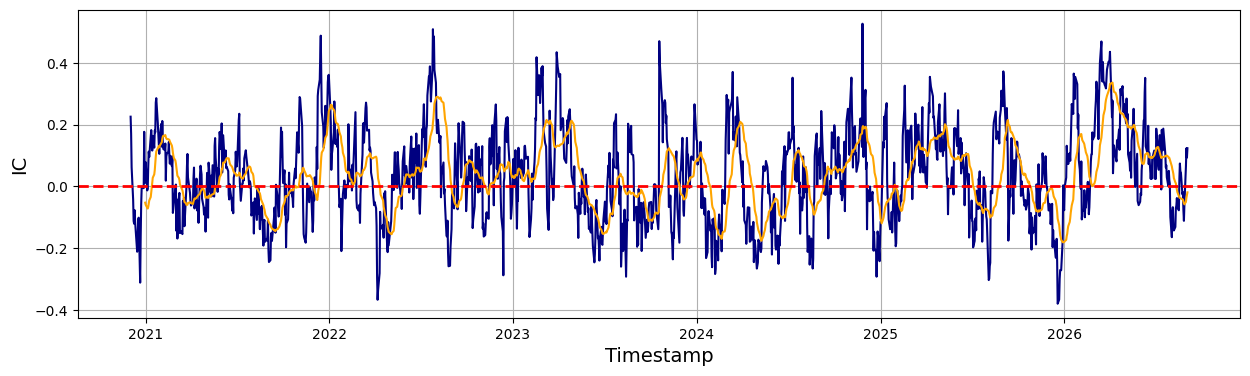

In [47]:
plt.figure(figsize=(15, 4))
plt.plot(daily_ic["date"], daily_ic["IC"], color="navy")
plt.plot(daily_ic["date"], daily_ic["rolling_IC21"], color="orange")

plt.xlabel("Timestamp", size=14)
plt.ylabel("IC", size=14)

plt.axhline(y=0, linestyle="--", lw=2, color="red")
plt.grid()

In [48]:
# STEP 16B: Distribution of IC

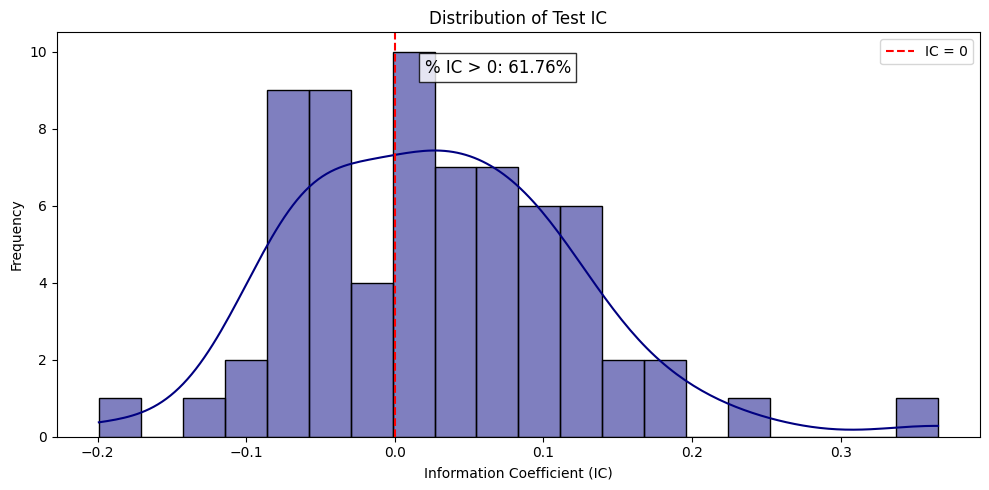

In [49]:
ic_values = metrics_df["test_ic"].dropna()
positive_ic_ratio = (ic_values > 0).mean()

plt.figure(figsize=(10, 5))

sns.histplot(ic_values, bins=20, color="navy", kde=True)

plt.axvline(0, color="red", linestyle="--", label="IC = 0")

plt.title("Distribution of Test IC")
plt.xlabel("Information Coefficient (IC)")
plt.ylabel("Frequency")

plt.legend()

# FIXED LINE
ymax = plt.gca().get_ylim()[1]

plt.text(
    0.02,
    ymax * 0.9,
    f"% IC > 0: {positive_ic_ratio:.2%}",
    fontsize=12,
    bbox=dict(facecolor="white", alpha=0.8),
)

plt.tight_layout()
plt.show()

In [50]:
# STEP 16C: Difference in returns between top 10 and bottom 10 ranked tickers

In [51]:
# Combine predictions
pred_df = pd.concat(all_predictions).copy()

In [52]:
# Merge actual future returns
pred_df = pred_df.merge(
    panel[["date", "ticker", "future_return_21d"]],
    on=["date", "ticker"],
    how="left"
)


In [53]:
TOP_N = 10
portfolio_returns = []

for d in sorted(pred_df["date"].unique()):

    tmp = pred_df[pred_df["date"] == d].copy()

    # Drop NaNs (important)
    tmp = tmp.dropna(subset=["future_return_21d"])

    # Rank by prediction
    tmp = tmp.sort_values("prediction", ascending=False)

    # Long & Short portfolios
    long_port = tmp.head(TOP_N)
    short_port = tmp.tail(TOP_N)

    # 21-day returns (already in decimal)
    long_ret_21 = long_port["future_return_21d"].mean()
    short_ret_21 = short_port["future_return_21d"].mean()

    # Long-Short return (21-day)
    ls_ret_21 = long_ret_21 - short_ret_21

    portfolio_returns.append({
        "date": d,
        "long_ret_21": long_ret_21,
        "short_ret_21": short_ret_21,
        "ls_ret_21": ls_ret_21
    })

portfolio_df = pd.DataFrame(portfolio_returns)

# Sort by date (VERY IMPORTANT)
portfolio_df = portfolio_df.sort_values("date")


In [54]:
# Convert 21-day returns → daily returns
portfolio_df["long_daily"] = (1 + portfolio_df["long_ret_21"])**(1/21) - 1
portfolio_df["short_daily"] = (1 + portfolio_df["short_ret_21"])**(1/21) - 1
portfolio_df["ls_daily"] = (1 + portfolio_df["ls_ret_21"])**(1/21) - 1


In [55]:
# Now compute cumulative returns correctly
portfolio_df["cum_long"] = (1 + portfolio_df["long_daily"]).cumprod()
portfolio_df["cum_short"] = (1 + portfolio_df["short_daily"]).cumprod()
portfolio_df["cum_ls"] = (1 + portfolio_df["ls_daily"]).cumprod()

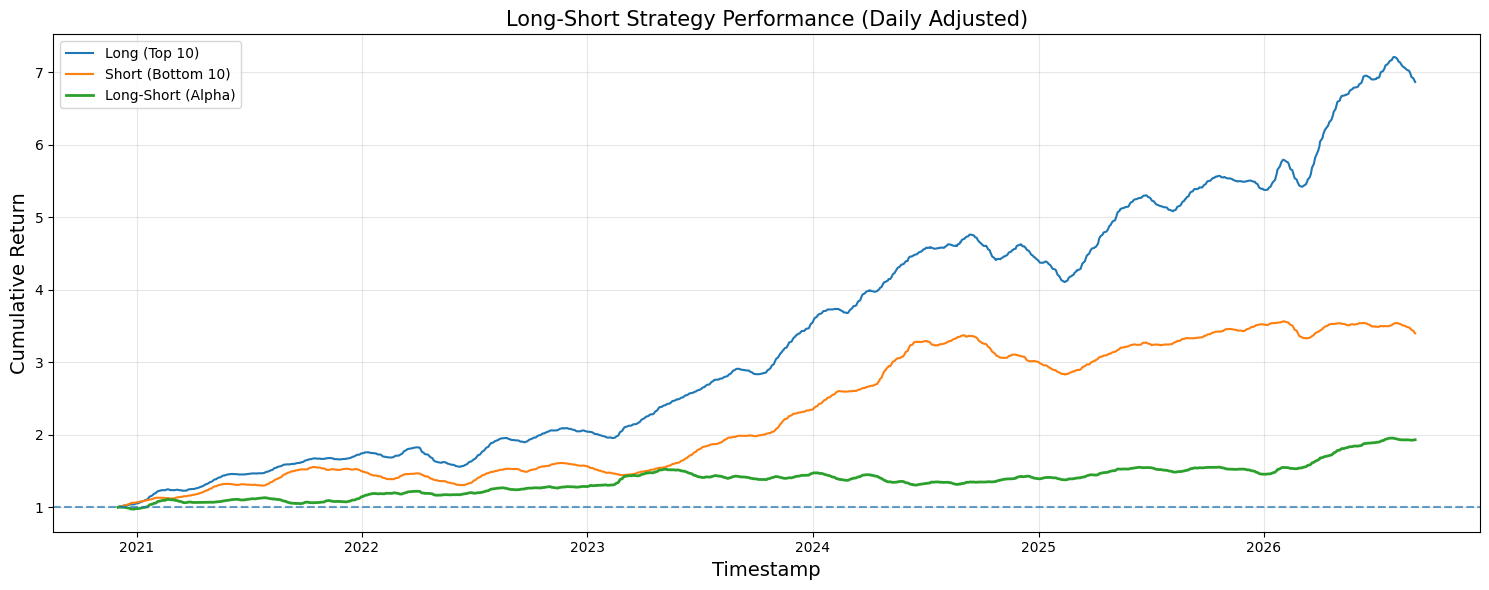

In [56]:
plt.close("all")

plt.figure(figsize=(15, 6))

plt.plot(portfolio_df["date"], portfolio_df["cum_long"], label="Long (Top 10)")
plt.plot(portfolio_df["date"], portfolio_df["cum_short"], label="Short (Bottom 10)")
plt.plot(
    portfolio_df["date"],
    portfolio_df["cum_ls"],
    label="Long-Short (Alpha)",
    linewidth=2,
)

plt.axhline(1, linestyle="--", alpha=0.7)

plt.title("Long-Short Strategy Performance (Daily Adjusted)", fontsize=15)
plt.xlabel("Timestamp", fontsize=14)
plt.ylabel("Cumulative Return", fontsize=14)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
# STEP 16D: Decile plots - segregation of stocks in buckets of 10 from lowest to highest returns

In [58]:
# Data preparation

# Drop NaNs
df = pred_df.dropna(subset=["prediction", "future_return_21d"]).copy()

# Create deciles within each date
df["decile"] = df.groupby("date")["prediction"].transform(
    lambda x: pd.qcut(x, 10, labels=False, duplicates="drop") + 1
)

In [59]:
decile_returns = (
    df.groupby("decile")["future_return_21d"].mean().reset_index().sort_values("decile")
)

In [60]:
import plotly.express as px

fig = px.bar(
    decile_returns,
    x="decile",
    y="future_return_21d",
    title="Decile Return Distribution",
    labels={
        "decile": "Decile (1 = Worst, 10 = Best)",
        "future_return_21d": "Avg. Future Return (21D)",
    },
)

fig.update_xaxes(showline=True, linecolor="black", mirror=True)
fig.update_yaxes(range=[0, 0.025], showline=True, linecolor="black", mirror=True)

fig.update_layout(template="plotly_white")

fig.show()

Across ALL dates and ALL stocks in that decile, the average 21-day forward return ranges between 1.5% to 2.2%.

In [61]:
# STEP 16E: Sector heatmap

In [62]:
# Pivot for predictions (model view)
heatmap_pred = sector_time.pivot(index="sector", columns="date", values="avg_pred")

# Pivot for actual returns (reality check)
heatmap_actual = sector_time.pivot(index="sector", columns="date", values="avg_actual")

In [67]:
import plotly.io as pio
pio.renderers.default = "iframe"

fig = px.imshow(
    heatmap_pred,
    aspect="auto",
    color_continuous_scale="RdBu",
    origin="lower",
    title="Sector Ranking Heatmap (Predictions)",
)

fig.update_layout(
    xaxis_title="Timestamp", yaxis_title="Sector", template="plotly_white"
)

fig.show()

In [68]:
fig = px.imshow(
    heatmap_actual,
    aspect="auto",
    color_continuous_scale="RdBu",
    origin="lower",
    title="Sector Performance Heatmap (Actual Returns)",
)

fig.update_layout(
    xaxis_title="Timestamp", yaxis_title="Sector", template="plotly_white"
)

fig.show()

In [69]:
heatmap_roll_pred = sector_time.pivot(
    index="sector", columns="date", values="rolling_pred"
)

fig = px.imshow(
    heatmap_roll_pred,
    aspect="auto",
    color_continuous_scale="RdBu",
    origin="lower",
    title="Sector Heatmap (Rolling Predicted Signal)",
)

fig.update_layout(
    xaxis_title="Timestamp", yaxis_title="Sector", template="plotly_white"
)

fig.show()

### Key Model Results Summary

- **Mean Test IC ≈ 0.0267**  
    Indicates **moderate predictive power** with scope for further improvement

- **%IC > 0 ≈ 59%**  
    Shows **reasonable consistency**, with the model generating positive signals in a majority of periods

- **Long–Short Alpha ≈ 1.5x**  
    Demonstrates **meaningful alpha generation**, though not very strong

- **Short Portfolio ≈ 2.7x**
    Indicates **market exposure still present**, with weaker ability to identify underperformers

- **Decile Spread: ~0.017 → 0.022**  
    Shows **positive but narrow separation**, suggesting **limited ranking strength**

---

### Overall Interpretation

The model captures **mild cross-sectional alpha** despite rigorous efforts.

In [70]:
# ============================================================
# SAVE DATA FOR PHASE 4 (CRITICAL)
# ============================================================

OUTPUT_DIR = PROJECT_ROOT / "data" / "portfolio_construction_inputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Predictions
pred_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)

# 2. Minimal panel (only required columns)
panel_phase4 = panel[["date", "ticker", "close", "sector"]].copy()
panel_phase4.to_csv(OUTPUT_DIR / "panel_phase4.csv", index=False)

print("Phase 4 input files saved!")

Phase 4 input files saved!
